In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# Build an absolute path from this notebook's parent directory
module_path = os.path.abspath(os.path.join("..", "data_importing"))
parent_path = os.path.abspath(os.path.join(".."))

# Add to sys.path if not already present
if module_path not in sys.path:
    sys.path.append(module_path)
if parent_path not in sys.path:
    sys.path.append(parent_path)

import processing as ps
from plotting import plotHdf5
from read_stave import read_stave_data_hdf5

# Match Filter Data

(1199,)
(6400, 325)
complex128


/home/amcdona4/Documents/frost-sas/src/frost_sas/processing.py:52: RuntimeWarning: divide by zero encountered in log10
  return 20 * np.log10(np.abs(data))


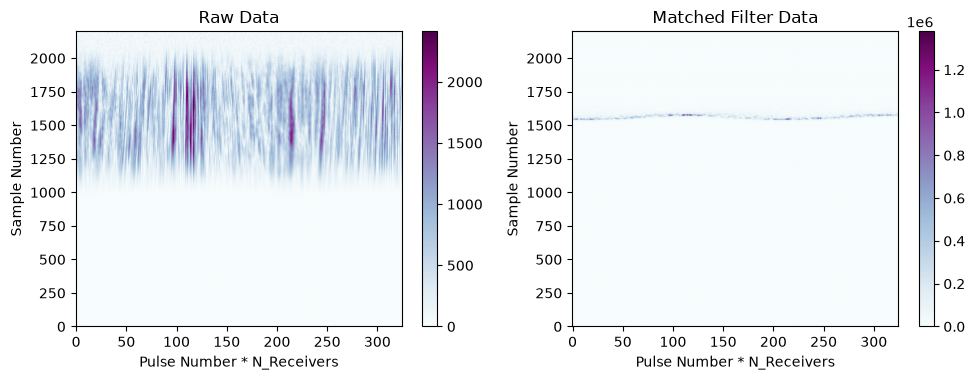

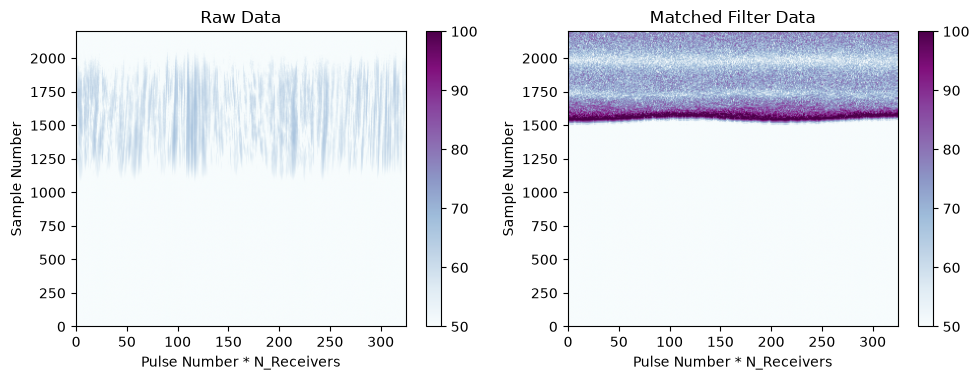

In [26]:
# filepath = Path("/home/amcdona4/Documents/frost-sas/mastodon_config/StaveData.hdf5")
filepath = None

if filepath is None:
    # print('Must specify stave data .json file on command line')
    # exit()
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()

    filename = filedialog.askopenfilename()
else:
    filename = sys.argv[1]

data = read_stave_data_hdf5(filename)

print(data.signal.signal.shape)
print(data.data.shape)
print(data.data.dtype)


matched_data = ps.match_filter(data.data, data.signal.signal)

# Plot the raw timeseries of the Tx Signal
# plt.plot(data.signal.signal)
# plt.title("Raw Tx Signal Timeseries")

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, figsize=(10, 3.9))

pos1 = ax1.imshow(
    abs(data.data), cmap="BuPu", aspect="auto"
)  # , extent=[-1,1,-10,10])
ax1.set_ylim(0, 2200)
ax1.set_title("Raw Data")
ax1.set_xlabel("Pulse Number * N_Receivers")
ax1.set_ylabel("Sample Number")
fig.colorbar(pos1, ax=ax1)

pos2 = ax2.imshow(
    abs(matched_data), cmap="BuPu", aspect="auto"
)  # , extent=[-1,1,-10,10])
ax2.set_ylim(0, 2200)
ax2.set_title("Matched Filter Data")
ax2.set_xlabel("Pulse Number * N_Receivers")
ax2.set_ylabel("Sample Number")
fig.colorbar(pos2, ax=ax2)

plt.tight_layout()

fig.savefig('raw_vs_matched_mag.png', dpi=300, bbox_inches='tight')


fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, figsize=(10, 3.9))

pos1 = ax1.imshow(
    ps.mag_to_db(data.data), cmap="BuPu", aspect="auto", vmin=50, vmax=100
)  # , extent=[-1,1,-10,10])
ax1.set_ylim(0, 2200)
ax1.set_title("Raw Data")
ax1.set_xlabel("Pulse Number * N_Receivers")
ax1.set_ylabel("Sample Number")
fig.colorbar(pos1, ax=ax1)

pos2 = ax2.imshow(
    ps.mag_to_db(matched_data), cmap="BuPu", aspect="auto",  vmin=50, vmax=100
)  # , extent=[-1,1,-10,10])
ax2.set_ylim(0, 2200)
ax2.set_title("Matched Filter Data")
ax2.set_xlabel("Pulse Number * N_Receivers")
ax2.set_ylabel("Sample Number")
fig.colorbar(pos2, ax=ax2)

plt.tight_layout()

fig.savefig('raw_vs_matched_db.png', dpi=300, bbox_inches='tight')


In [8]:
print("Numpy mag2db Time")
%timeit ps.mag_to_db(data.data)
print("Numba mag2db Time")
%timeit ps.mag_to_db(data.data)

Numpy mag2db Time


/home/amcdona4/Documents/frost-sas/src/frost_sas/processing.py:52: RuntimeWarning: divide by zero encountered in log10
  return 20 * np.log10(np.abs(data))


15.9 ms ± 32.8 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
Numba mag2db Time
15.9 ms ± 230 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [9]:
print("Scipy Matched Filter Time")
%timeit ps.match_filter(data.data, data.signal.signal)
print("Numba Matched Filter")
%timeit ps.match_filter_numba(data.data, data.signal.signal)

Scipy Matched Filter Time
64.2 ms ± 420 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
Numba Matched Filter
209 ms ± 11.6 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
